# Rectify a WALLE courtship-signal video

This notebook applies the OpenCV stereo calibration produced by `01_stereo_rectification_walle.ipynb` to a biological video. The worked example is the `southpan1` *Photeros annecohenae* courtship signal recorded at Southwater Caye in 2019.

The historical analysis used left-camera frames 23,900–24,250 and a right-camera offset of −13 frames. Thus, left frame 23,900 is paired with right frame 23,887. The end frame is exclusive, giving 350 synchronized pairs.

## 1. Imports and project paths

Run this notebook with the `manta` conda kernel. Large source and output videos are deliberately excluded from Git.

In [1]:
from pathlib import Path
import os
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from stereo_calibration import rectify_pair

print('Project root:', PROJECT_ROOT)

Project root: /Users/oakley/Documents/GitHub/manta-analysis


## 2. Configure the Southwater signal clip

The default filenames reproduce the original WALL-E/Nextflow naming scheme. If the full videos are elsewhere, set the `MANTA_SOUTHPAN1_LEFT` and `MANTA_SOUTHPAN1_RIGHT` environment variables or edit the two paths below.

If you instead have synchronized, unrectified 350-frame clips, set `INPUTS_ARE_PRECLIPPED = True` and point the paths to those clips.

In [2]:
WALL_E_ROOT = Path(os.environ.get(
    'WALL_E_ROOT',
    '/Users/oakley/Documents/GitHub/WALL-E/nextflow',
))

LEFT_VIDEO = Path(os.environ.get(
    'MANTA_SOUTHPAN1_LEFT',
    WALL_E_ROOT / 'video_data/cfr_southpan1185538-1_L.mkv',
))
RIGHT_VIDEO = Path(os.environ.get(
    'MANTA_SOUTHPAN1_RIGHT',
    WALL_E_ROOT / 'video_data/cfr_southpan1185539-2_R.mkv',
))

INPUTS_ARE_PRECLIPPED = False
LEFT_START_FRAME = 23_900
RIGHT_FRAME_OFFSET = -13
END_FRAME = 24_250  # exclusive, in the left-camera timeline
N_FRAMES = END_FRAME - LEFT_START_FRAME
RIGHT_START_FRAME = LEFT_START_FRAME + RIGHT_FRAME_OFFSET

CALIBRATION_FILE = PROJECT_ROOT / 'data/processed/2019southwater_stereo_calibration.npz'
OUTPUT_DIR = PROJECT_ROOT / 'data/processed/southwater2019'
OUTPUT_LEFT = OUTPUT_DIR / 'southpan1_rectified_left.mp4'
OUTPUT_RIGHT = OUTPUT_DIR / 'southpan1_rectified_right.mp4'
OVERWRITE_OUTPUTS = True

# Historical southpan1 contour-detection settings from southwater2019_clips.csv
CONTOUR_THRESHOLD = 130  # grayscale pixels above this value are candidate signal
MIN_CONTOUR_AREA = 0.1   # pixels squared; intentionally retains very small flashes

if INPUTS_ARE_PRECLIPPED:
    LEFT_START_FRAME = RIGHT_START_FRAME = 0

print('Left source: ', LEFT_VIDEO)
print('Right source:', RIGHT_VIDEO)
print(f'Paired source frames: left {LEFT_START_FRAME}, right {RIGHT_START_FRAME}')
print('Frames to rectify:', N_FRAMES)
print('Calibration:', CALIBRATION_FILE)
print(f'Contour settings: threshold={CONTOUR_THRESHOLD}, minimum area={MIN_CONTOUR_AREA}')

Left source:  /Users/oakley/Documents/GitHub/WALL-E/nextflow/video_data/cfr_southpan1185538-1_L.mkv
Right source: /Users/oakley/Documents/GitHub/WALL-E/nextflow/video_data/cfr_southpan1185539-2_R.mkv
Paired source frames: left 23900, right 23887
Frames to rectify: 350
Calibration: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/2019southwater_stereo_calibration.npz
Contour settings: threshold=130, minimum area=0.1


## 3. Load and validate the calibration

Notebook 01 saves camera matrices, distortion coefficients, stereo geometry, and precomputed remapping arrays in one portable `.npz` archive. The map dimensions must match the signal-video dimensions.

In [3]:
if not CALIBRATION_FILE.exists():
    raise FileNotFoundError(
        f'{CALIBRATION_FILE} does not exist. Run notebook 01 first.'
    )
missing_videos = [path for path in (LEFT_VIDEO, RIGHT_VIDEO) if not path.exists()]
if missing_videos:
    missing = '\n'.join(f'  - {path}' for path in missing_videos)
    raise FileNotFoundError(
        'The full Southwater source videos are not currently at the configured paths:\n'
        f'{missing}\nSet MANTA_SOUTHPAN1_LEFT and MANTA_SOUTHPAN1_RIGHT, '
        'or edit LEFT_VIDEO and RIGHT_VIDEO.'
    )

with np.load(CALIBRATION_FILE) as archive:
    calibration = {name: archive[name] for name in archive.files}

def video_metadata(path):
    cap = cv2.VideoCapture(str(path))
    if not cap.isOpened():
        raise RuntimeError(f'OpenCV could not open {path}')
    metadata = {
        'width': int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
        'height': int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
        'fps': cap.get(cv2.CAP_PROP_FPS),
        'frames': int(cap.get(cv2.CAP_PROP_FRAME_COUNT)),
    }
    cap.release()
    return metadata

left_metadata = video_metadata(LEFT_VIDEO)
right_metadata = video_metadata(RIGHT_VIDEO)
expected_size = tuple(int(value) for value in calibration['image_size'])
actual_left = (left_metadata['width'], left_metadata['height'])
actual_right = (right_metadata['width'], right_metadata['height'])
if actual_left != expected_size or actual_right != expected_size:
    raise ValueError(
        f'Calibration expects {expected_size}; videos are {actual_left} and {actual_right}.'
    )
if LEFT_START_FRAME + N_FRAMES > left_metadata['frames']:
    raise ValueError('The requested left-camera interval extends beyond the video.')
if RIGHT_START_FRAME < 0 or RIGHT_START_FRAME + N_FRAMES > right_metadata['frames']:
    raise ValueError('The requested right-camera interval extends beyond the video.')

print('Left metadata: ', left_metadata)
print('Right metadata:', right_metadata)
print('Calibration image size:', expected_size)
print('Estimated baseline:', np.linalg.norm(calibration['translation']), 'mm')

Left metadata:  {'width': 640, 'height': 480, 'fps': 29.97002997002997, 'frames': 53947}
Right metadata: {'width': 640, 'height': 480, 'fps': 29.97002997002997, 'frames': 53947}
Calibration image size: (640, 480)
Estimated baseline: 100.90501087960229 mm


## 4. Find an informative synchronized frame

Rather than showing an arbitrary first or middle frame, scan the clip using the original `southpan1` contour settings. We prefer a frame with detections in **both** cameras, then rank candidates by the number and total area of detected contours. The frame images are displayed at their native brightness—there is no automatic contrast stretch.

Selected output frame 68
Source frames: left 23968, right 23955
Detected contours: left 1, right 1
Contour areas, left: [86.5]
Contour areas, right: [69.5]


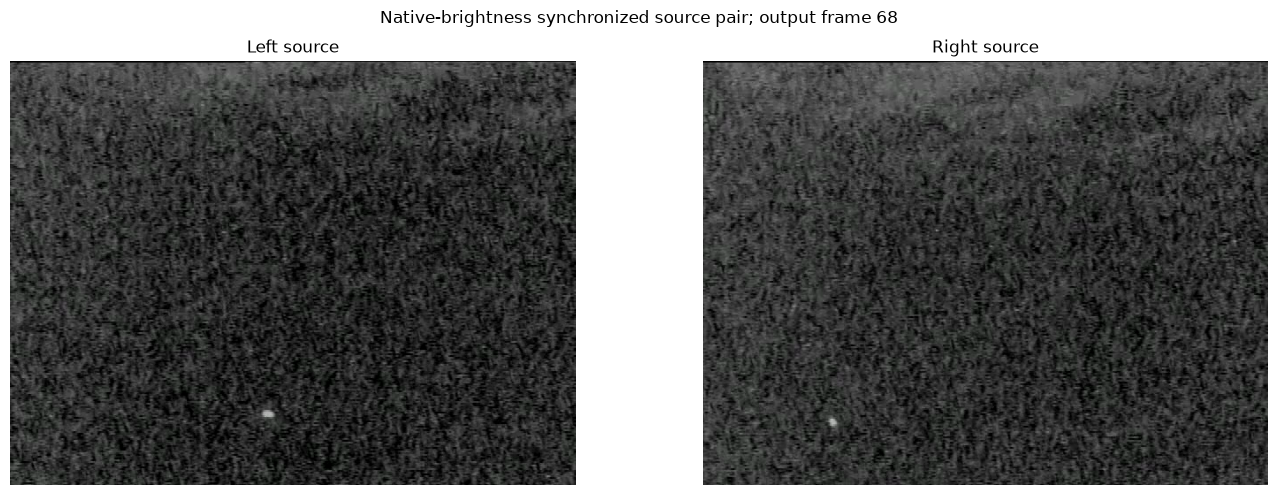

In [4]:
def read_frame(path, frame_number):
    cap = cv2.VideoCapture(str(path))
    cap.set(cv2.CAP_PROP_POS_FRAMES, frame_number)
    ok, frame = cap.read()
    cap.release()
    if not ok:
        raise RuntimeError(f'Could not read frame {frame_number} from {path}')
    return frame

def detect_bright_contours(frame, threshold=CONTOUR_THRESHOLD, min_area=MIN_CONTOUR_AREA):
    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)
    _, mask = cv2.threshold(gray, threshold, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(mask, cv2.RETR_TREE, cv2.CHAIN_APPROX_SIMPLE)
    contours = [contour for contour in contours if cv2.contourArea(contour) > min_area]
    return mask, contours

def find_informative_pair(left_path, right_path, calibration, left_start, right_start, n_frames):
    cap_left = cv2.VideoCapture(str(left_path))
    cap_right = cv2.VideoCapture(str(right_path))
    cap_left.set(cv2.CAP_PROP_POS_FRAMES, left_start)
    cap_right.set(cv2.CAP_PROP_POS_FRAMES, right_start)
    best = None
    try:
        for output_frame in range(n_frames):
            ok_left, source_left = cap_left.read()
            ok_right, source_right = cap_right.read()
            if not (ok_left and ok_right):
                raise RuntimeError(f'Video read failed while scanning frame {output_frame}.')
            rectified_left, rectified_right = rectify_pair(source_left, source_right, calibration)
            _, contours_left = detect_bright_contours(rectified_left)
            _, contours_right = detect_bright_contours(rectified_right)
            areas = [cv2.contourArea(c) for c in contours_left + contours_right]
            score = (
                int(bool(contours_left) and bool(contours_right)),
                min(len(contours_left), len(contours_right)),
                len(contours_left) + len(contours_right),
                sum(areas),
            )
            if best is None or score > best['score']:
                best = {
                    'output_frame': output_frame, 'score': score,
                    'source_left': source_left.copy(), 'source_right': source_right.copy(),
                    'rectified_left': rectified_left, 'rectified_right': rectified_right,
                    'contours_left': contours_left, 'contours_right': contours_right,
                }
    finally:
        cap_left.release(); cap_right.release()
    return best

preview = find_informative_pair(
    LEFT_VIDEO, RIGHT_VIDEO, calibration,
    LEFT_START_FRAME, RIGHT_START_FRAME, N_FRAMES,
)
PREVIEW_FRAME = preview['output_frame']
print(f'Selected output frame {PREVIEW_FRAME}')
print(f'Source frames: left {LEFT_START_FRAME + PREVIEW_FRAME}, right {RIGHT_START_FRAME + PREVIEW_FRAME}')
print(f'Detected contours: left {len(preview["contours_left"])}, right {len(preview["contours_right"])}')
print('Contour areas, left:', [round(cv2.contourArea(c), 1) for c in preview['contours_left']])
print('Contour areas, right:', [round(cv2.contourArea(c), 1) for c in preview['contours_right']])

figure, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for axis, image, camera in zip(
    axes, [preview['source_left'], preview['source_right']], ['Left source', 'Right source']
):
    axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axis.set_title(camera)
    axis.axis('off')
figure.suptitle(f'Native-brightness synchronized source pair; output frame {PREVIEW_FRAME}')
plt.tight_layout()

## 5. Preview rectification and detected contours

The top row shows the rectified frames at native brightness. Accepted contours are outlined in blue and marked with a larger blue circle so even a very small flash is easy to locate. The bottom row shows the exact binary masks used for detection.

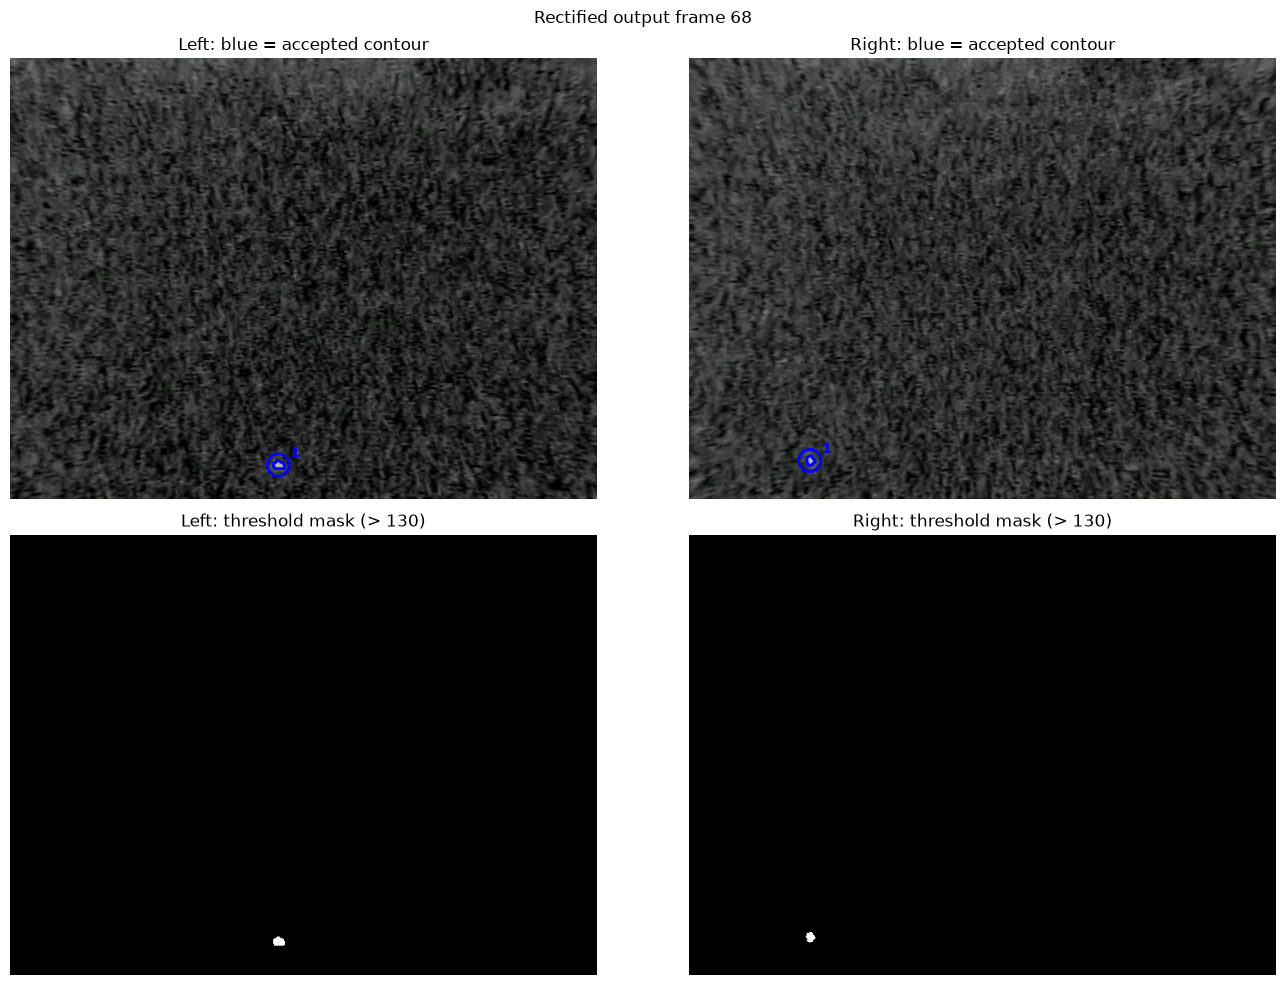

In [5]:
def annotate_contours(frame, contours):
    annotated = frame.copy()
    cv2.drawContours(annotated, contours, -1, (255, 0, 0), 2)  # blue in BGR
    for index, contour in enumerate(contours, start=1):
        moments = cv2.moments(contour)
        if moments['m00'] == 0:
            continue
        center = (int(moments['m10'] / moments['m00']), int(moments['m01'] / moments['m00']))
        cv2.circle(annotated, center, 12, (255, 0, 0), 2)
        cv2.putText(annotated, str(index), (center[0] + 14, center[1] - 8),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 0, 0), 2, cv2.LINE_AA)
    return annotated

rectified_pair = [preview['rectified_left'], preview['rectified_right']]
contour_pair = [preview['contours_left'], preview['contours_right']]
mask_pair = [detect_bright_contours(frame)[0] for frame in rectified_pair]
annotated_pair = [annotate_contours(frame, contours) for frame, contours in zip(rectified_pair, contour_pair)]

figure, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for column, camera in enumerate(['Left', 'Right']):
    axes[0, column].imshow(cv2.cvtColor(annotated_pair[column], cv2.COLOR_BGR2RGB))
    axes[0, column].set_title(f'{camera}: blue = accepted contour')
    axes[1, column].imshow(mask_pair[column], cmap='gray', vmin=0, vmax=255)
    axes[1, column].set_title(f'{camera}: threshold mask (> {CONTOUR_THRESHOLD})')
    for row in range(2):
        axes[row, column].axis('off')
figure.suptitle(f'Rectified output frame {PREVIEW_FRAME}')
plt.tight_layout()

## 6. Rectify and write the 350-frame signal clip

The two writers use the same frame rate, dimensions, codec, and number of frames. The outputs are ignored by Git because they are generated data.

In [6]:
def rectify_video_interval(
    left_path, right_path, calibration, left_start, right_start, n_frames,
    output_left, output_right, overwrite=False,
):
    output_left, output_right = Path(output_left), Path(output_right)
    if not overwrite and (output_left.exists() or output_right.exists()):
        raise FileExistsError('Output exists. Set OVERWRITE_OUTPUTS=True to replace it.')
    output_left.parent.mkdir(parents=True, exist_ok=True)

    cap_left = cv2.VideoCapture(str(left_path))
    cap_right = cv2.VideoCapture(str(right_path))
    cap_left.set(cv2.CAP_PROP_POS_FRAMES, left_start)
    cap_right.set(cv2.CAP_PROP_POS_FRAMES, right_start)
    fps = cap_left.get(cv2.CAP_PROP_FPS)
    if not np.isfinite(fps) or fps <= 0:
        fps = 30.0
    width, height = (int(value) for value in calibration['image_size'])
    codec = cv2.VideoWriter_fourcc(*'mp4v')
    writer_left = cv2.VideoWriter(str(output_left), codec, fps, (width, height))
    writer_right = cv2.VideoWriter(str(output_right), codec, fps, (width, height))
    if not writer_left.isOpened() or not writer_right.isOpened():
        raise RuntimeError('Could not initialize one or both output video writers.')

    written = 0
    try:
        for index in range(n_frames):
            ok_left, frame_left = cap_left.read()
            ok_right, frame_right = cap_right.read()
            if not (ok_left and ok_right):
                raise RuntimeError(f'Video read failed at output frame {index}.')
            rectified_left, rectified_right = rectify_pair(
                frame_left, frame_right, calibration
            )
            writer_left.write(rectified_left)
            writer_right.write(rectified_right)
            written += 1
    finally:
        cap_left.release(); cap_right.release()
        writer_left.release(); writer_right.release()

    return {'frames': written, 'fps': fps, 'size': (width, height)}

result = rectify_video_interval(
    LEFT_VIDEO, RIGHT_VIDEO, calibration,
    LEFT_START_FRAME, RIGHT_START_FRAME, N_FRAMES,
    OUTPUT_LEFT, OUTPUT_RIGHT, overwrite=OVERWRITE_OUTPUTS,
)
print('Rectification complete:', result)
print('Left output: ', OUTPUT_LEFT)
print('Right output:', OUTPUT_RIGHT)

Rectification complete: {'frames': 350, 'fps': 29.97002997002997, 'size': (640, 480)}
Left output:  /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_rectified_left.mp4
Right output: /Users/oakley/Documents/GitHub/manta-analysis/data/processed/southwater2019/southpan1_rectified_right.mp4


## 7. Verify the written outputs

This checks that both clips contain the expected number of frames and confirms that the selected biological contours survive video encoding. These files become the inputs to the courtship-signal measurement notebook.

Left output:  {'width': 640, 'height': 480, 'fps': 29.97, 'frames': 350}
Right output: {'width': 640, 'height': 480, 'fps': 29.97, 'frames': 350}


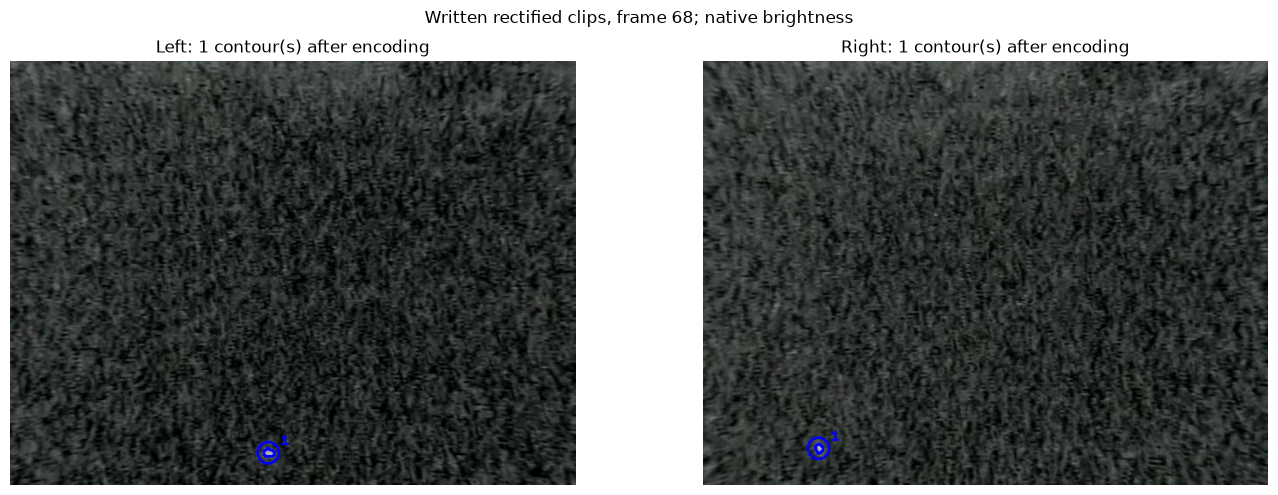

In [7]:
output_left_metadata = video_metadata(OUTPUT_LEFT)
output_right_metadata = video_metadata(OUTPUT_RIGHT)
print('Left output: ', output_left_metadata)
print('Right output:', output_right_metadata)
if output_left_metadata['frames'] != N_FRAMES or output_right_metadata['frames'] != N_FRAMES:
    raise RuntimeError('An output has an unexpected frame count.')

final_left = read_frame(OUTPUT_LEFT, PREVIEW_FRAME)
final_right = read_frame(OUTPUT_RIGHT, PREVIEW_FRAME)
final_masks_and_contours = [detect_bright_contours(frame) for frame in (final_left, final_right)]
final_annotated = [
    annotate_contours(frame, mask_and_contours[1])
    for frame, mask_and_contours in zip((final_left, final_right), final_masks_and_contours)
]
figure, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for axis, image, camera, mask_and_contours in zip(
    axes, final_annotated, ['Left', 'Right'], final_masks_and_contours
):
    axis.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    axis.set_title(f'{camera}: {len(mask_and_contours[1])} contour(s) after encoding')
    axis.axis('off')
figure.suptitle(f'Written rectified clips, frame {PREVIEW_FRAME}; native brightness')
plt.tight_layout()

## Next step

The next notebook will measure the courtship signal from these rectified clips: detect luminous contours, join detections into pulses, match pulses between cameras, triangulate 3D positions using this same calibration, curate the focal signal train, and calculate pulse-level behavioral measurements.